In [1]:
from pathlib import Path
import pandas as pd

pasta_atual = Path.cwd()

if (pasta_atual / "dados").is_dir():
    pasta_dados = pasta_atual / "dados"
elif (pasta_atual.parent / "dados").is_dir():
    pasta_dados = pasta_atual.parent / "dados"
else:
    raise FileNotFoundError(
        "Pasta 'dados' não encontrada. Confira onde o projeto está aberto."
    )

tmdb = pd.read_csv(pasta_dados / "tmdb_5000_movies.csv")
filmes = pd.read_csv(pasta_dados / "movies.csv")
avaliacoes = pd.read_csv(pasta_dados / "ratings.csv")

bases = {
    "TMDB": tmdb,
    "Filmes": filmes,
    "Avaliações": avaliacoes,
}

for nome, base in bases.items():
    print(f"{nome}: {base.shape[0]:,} linhas e {base.shape[1]} colunas")

TMDB: 4,803 linhas e 20 colunas
Filmes: 9,742 linhas e 3 colunas
Avaliações: 100,836 linhas e 4 colunas


In [2]:
for nome, base in bases.items():
    print(f"\n{'=' * 50}")
    print(nome)
    print(f"{'=' * 50}")

    display(base.head())

    base.info()

    print(f"\nLinhas totalmente duplicadas: {base.duplicated().sum()}")

    diagnostico = pd.DataFrame({
        "tipo": base.dtypes.astype(str),
        "ausentes": base.isna().sum(),
        "ausentes_pct": base.isna().mean().mul(100).round(2),
    })

    display(
        diagnostico.sort_values("ausentes", ascending=False)
    )


TMDB


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

,tipo,ausentes,ausentes_pct
homepage,str,3091,64.36
tagline,str,844,17.57
overview,str,3,0.06
runtime,float64,2,0.04
release_date,str,1,0.02
id,int64,0,0.00
budget,int64,0,0.00
genres,str,0,0.00
original_title,str,0,0.00
popularity,float64,0,0.00



Filmes


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


... (2 outputs left out)


Avaliações


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Linhas totalmente duplicadas: 0


,tipo,ausentes,ausentes_pct
userId,int64,0,0.0
movieId,int64,0,0.0
rating,float64,0,0.0
timestamp,int64,0,0.0


In [3]:
print("IDs repetidos na TMDB:", tmdb["id"].duplicated().sum())
print("IDs repetidos em Filmes:", filmes["movieId"].duplicated().sum())

print(
    "Pares usuário-filme repetidos:",
    avaliacoes.duplicated(subset=["userId", "movieId"]).sum()
)

print("Usuários distintos:", avaliacoes["userId"].nunique())
print("Filmes distintos avaliados:", avaliacoes["movieId"].nunique())

avaliacoes_sem_filme = ~avaliacoes["movieId"].isin(filmes["movieId"])

print(
    "Avaliações sem filme cadastrado:",
    avaliacoes_sem_filme.sum()
)

print(
    "Filmes cadastrados sem avaliações:",
    (~filmes["movieId"].isin(avaliacoes["movieId"])).sum()
)

IDs repetidos na TMDB: 0
IDs repetidos em Filmes: 0
Pares usuário-filme repetidos: 0
Usuários distintos: 610
Filmes distintos avaliados: 9724
Avaliações sem filme cadastrado: 0
Filmes cadastrados sem avaliações: 18


In [4]:
colunas_numericas = [
    "budget", "revenue", "runtime",
    "popularity", "vote_average", "vote_count"
]

resumo_numerico = pd.DataFrame({
    "ausentes": tmdb[colunas_numericas].isna().sum(),
    "zeros": tmdb[colunas_numericas].eq(0).sum(),
    "negativos": tmdb[colunas_numericas].lt(0).sum(),
    "minimo": tmdb[colunas_numericas].min(),
    "maximo": tmdb[colunas_numericas].max(),
})

display(resumo_numerico)

colunas_listas = [
    "genres", "keywords", "production_companies",
    "production_countries", "spoken_languages"
]

listas_vazias = (
    tmdb[colunas_listas]
    .apply(lambda coluna: coluna.str.strip().eq("[]").sum())
    .rename("listas_vazias")
    .to_frame()
)

display(listas_vazias)

,ausentes,zeros,negativos,minimo,maximo
budget,0,1037,0,0.0,3.800000e+08
revenue,0,1427,0,0.0,2.787965e+09
runtime,2,35,0,0.0,3.380000e+02
popularity,0,1,0,0.0,8.755813e+02
vote_average,0,63,0,0.0,1.000000e+01
vote_count,0,62,0,0.0,1.375200e+04


,listas_vazias
genres,28
keywords,412
production_companies,351
production_countries,174
spoken_languages,86


In [5]:
display(
    tmdb.loc[
        tmdb["runtime"].isna() | tmdb["release_date"].isna(),
        ["id", "title", "release_date", "runtime", "budget", "revenue"]
    ]
)

print("Quantidade de avaliações por nota:")

display(
    avaliacoes["rating"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("nota")
    .to_frame("quantidade")
)

,id,title,release_date,runtime,budget,revenue
2656,370980,Chiamatemi Francesco - Il Papa della gente,2015-12-03,NaN,15000000,0
4140,459488,"To Be Frank, Sinatra at 100",2015-12-12,NaN,2,0
4553,380097,America Is Still the Place,NaN,0.0,0,0


Quantidade de avaliações por nota:


,quantidade
nota,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


In [6]:
tmdb_tratado = tmdb.copy()
filmes_tratados = filmes.copy()
avaliacoes_tratadas = avaliacoes.copy()

tmdb_tratado["release_date"] = pd.to_datetime(
    tmdb["release_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

tmdb_tratado["ano_lancamento"] = (
    tmdb_tratado["release_date"].dt.year.astype("Int64")
)

avaliacoes_tratadas["data_avaliacao"] = pd.to_datetime(
    avaliacoes["timestamp"],
    unit="s",
    origin="unix",
    utc=True,
    errors="coerce"
)

datas_invalidas = (
    tmdb["release_date"].notna()
    & tmdb_tratado["release_date"].isna()
)

print("Datas de lançamento que falharam na conversão:", datas_invalidas.sum())
print(
    "Datas de avaliação que falharam na conversão:",
    avaliacoes_tratadas["data_avaliacao"].isna().sum()
)

Datas de lançamento que falharam na conversão: 0
Datas de avaliação que falharam na conversão: 0


In [7]:
tmdb_tratado["orcamento_analise"] = (
    tmdb_tratado["budget"].where(tmdb_tratado["budget"] > 0)
)

tmdb_tratado["receita_analise"] = (
    tmdb_tratado["revenue"].where(tmdb_tratado["revenue"] > 0)
)

tmdb_tratado["duracao_analise"] = (
    tmdb_tratado["runtime"].where(tmdb_tratado["runtime"] > 0)
)

tmdb_tratado["nota_analise"] = (
    tmdb_tratado["vote_average"]
    .where(tmdb_tratado["vote_count"] > 0)
)

tmdb_tratado["dados_financeiros_positivos"] = (
    tmdb_tratado["orcamento_analise"].notna()
    & tmdb_tratado["receita_analise"].notna()
)

print(
    "Filmes com orçamento e receita positivos:",
    tmdb_tratado["dados_financeiros_positivos"].sum()
)

display(
    tmdb_tratado[
        ["orcamento_analise", "receita_analise", "duracao_analise", "nota_analise"]
    ].isna().sum().rename("ausentes").to_frame()
)

Filmes com orçamento e receita positivos: 3229


,ausentes
orcamento_analise,1037
receita_analise,1427
duracao_analise,37
nota_analise,62


In [8]:
for coluna in ["budget", "revenue"]:
    print(f"\n15 menores valores positivos de {coluna}:")

    display(
        tmdb_tratado.loc[
            tmdb_tratado[coluna] > 0,
            ["id", "title", "ano_lancamento", "budget", "revenue"]
        ]
        .nsmallest(15, coluna)
    )


15 menores valores positivos de budget:


,id,title,ano_lancamento,budget,revenue
4238,3082,Modern Times,1936,1,8500000
4247,361505,Me You and Five Bucks,2015,1,0
4251,46729,Fetching Cody,2005,1,0
4262,48463,Incident at Loch Ness,2004,1,0
4293,357834,The Algerian,2015,1,0
4369,37532,Slam,1998,1,0
4424,287524,Fear Clinic,2014,1,0
4140,459488,"To Be Frank, Sinatra at 100",2015,2,0
3967,79587,Four Single Fathers,2009,3,0
3611,22649,A Farewell to Arms,1932,4,25



15 menores valores positivos de revenue:


,id,title,ano_lancamento,budget,revenue
3372,13006,Split Second,1992,7,5
3419,38415,Bran Nue Dae,2009,7,7
3875,108346,Dreaming of Joseph Lees,1999,2000000,7
3428,10496,Bats,1999,0,10
2933,28932,F.I.S.T.,1978,11,11
3131,217708,Of Horses and Men,2013,10,11
1655,14844,Chasing Liberty,2004,23000000,12
2485,18475,The Cookout,2004,16000000,12
1912,10397,Angela's Ashes,1999,25,13
1771,1613,The 51st State,2001,28,14


In [9]:
financeiros_positivos = tmdb_tratado.loc[
    tmdb_tratado["dados_financeiros_positivos"]
].copy()

comparacao_limites = []

for limite in [0, 100, 1_000, 10_000]:
    mantidos = (
        (financeiros_positivos["budget"] > limite)
        & (financeiros_positivos["revenue"] > limite)
    )

    comparacao_limites.append({
        "limite_exclusivo": limite,
        "filmes_mantidos": int(mantidos.sum()),
        "filmes_excluidos": int((~mantidos).sum()),
        "percentual_mantido": round(mantidos.mean() * 100, 2),
    })

display(pd.DataFrame(comparacao_limites))

,limite_exclusivo,filmes_mantidos,filmes_excluidos,percentual_mantido
0,0,3229,0,100.00
1,100,3213,16,99.50
2,1000,3211,18,99.44
3,10000,3203,26,99.19


In [10]:
import json

def extrair_generos(texto):
    itens = json.loads(texto)

    if not isinstance(itens, list):
        raise ValueError("O campo de gêneros precisa conter uma lista.")

    return [item["name"] for item in itens]

tmdb_tratado["generos_lista"] = (
    tmdb_tratado["genres"].apply(extrair_generos)
)

tmdb_tratado["quantidade_generos"] = (
    tmdb_tratado["generos_lista"].str.len()
)

display(
    tmdb_tratado[
        ["title", "generos_lista", "quantidade_generos"]
    ].head()
)

print(
    "Filmes sem gênero informado:",
    tmdb_tratado["quantidade_generos"].eq(0).sum()
)

,title,generos_lista,quantidade_generos
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]",4
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]",3
2,Spectre,"[Action, Adventure, Crime]",3
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",4
4,John Carter,"[Action, Adventure, Science Fiction]",3


Filmes sem gênero informado: 28


In [11]:
filmes_tratados["generos_lista"] = (
    filmes_tratados["genres"]
    .apply(
        lambda texto: [
            genero
            for genero in texto.split("|")
            if genero and genero != "(no genres listed)"
        ]
    )
)

display(
    filmes_tratados[
        ["movieId", "title", "generos_lista"]
    ].head()
)

print(
    "Filmes sem gênero informado:",
    filmes_tratados["generos_lista"].str.len().eq(0).sum()
)

,movieId,title,generos_lista
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men (1995),"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]"
4,5,Father of the Bride Part II (1995),[Comedy]


Filmes sem gênero informado: 34


In [12]:
tmdb_generos = (
    tmdb_tratado[["id", "generos_lista"]]
    .explode("generos_lista")
    .rename(columns={"generos_lista": "genero"})
    .dropna(subset=["genero"])
    .drop_duplicates(subset=["id", "genero"])
    .reset_index(drop=True)
)

display(tmdb_generos.head(10))

print("Relações filme–gênero:", len(tmdb_generos))
print("Filmes com gênero:", tmdb_generos["id"].nunique())

,id,genero
0,19995,Action
1,19995,Adventure
2,19995,Fantasy
3,19995,Science Fiction
4,285,Adventure
5,285,Fantasy
6,285,Action
7,206647,Action
8,206647,Adventure
9,206647,Crime


Relações filme–gênero: 12160
Filmes com gênero: 4775


In [13]:
resumo_cenarios = []

for limite in [0, 100, 1_000, 10_000]:
    recorte = financeiros_positivos.loc[
        (financeiros_positivos["budget"] > limite)
        & (financeiros_positivos["revenue"] > limite)
    ].copy()

    multiplo = recorte["revenue"] / recorte["budget"]

    resumo_cenarios.append({
        "limite_exclusivo": limite,
        "filmes": len(recorte),
        "orcamento_mediano": recorte["budget"].median(),
        "receita_mediana": recorte["revenue"].median(),
        "multiplo_mediano": multiplo.median(),
        "receita_maior_orcamento_pct": (
            recorte["revenue"].gt(recorte["budget"]).mean() * 100
        ),
    })

display(pd.DataFrame(resumo_cenarios).round(2))

,limite_exclusivo,filmes,orcamento_mediano,receita_mediana,multiplo_mediano,receita_maior_orcamento_pct
0,0,3229,25000000.0,55184721.0,2.3,75.50
1,100,3213,25000000.0,55969000.0,2.3,75.69
2,1000,3211,25000000.0,55987321.0,2.3,75.71
3,10000,3203,25530000.0,56308881.0,2.3,75.80


In [14]:
LIMITE_FINANCEIRO = 1_000

tmdb_tratado["incluido_recorte_financeiro"] = (
    tmdb_tratado["budget"].gt(LIMITE_FINANCEIRO)
    & tmdb_tratado["revenue"].gt(LIMITE_FINANCEIRO)
)

cinema_financeiro = tmdb_tratado.loc[
    tmdb_tratado["incluido_recorte_financeiro"]
].copy()

cinema_financeiro["multiplo_receita_orcamento"] = (
    cinema_financeiro["revenue"] / cinema_financeiro["budget"]
)

print("Filmes no recorte financeiro:", len(cinema_financeiro))
print(
    "Cobertura da base TMDB:",
    f"{len(cinema_financeiro) / len(tmdb_tratado):.2%}"
)

Filmes no recorte financeiro: 3211
Cobertura da base TMDB: 66.85%


In [15]:
financeiro_por_genero = tmdb_generos.merge(
    cinema_financeiro[
        ["id", "budget", "revenue", "multiplo_receita_orcamento"]
    ],
    on="id",
    how="inner",
    validate="many_to_one"
)

resumo_generos = (
    financeiro_por_genero
    .groupby("genero")
    .agg(
        filmes=("id", "nunique"),
        orcamento_mediano=("budget", "median"),
        receita_mediana=("revenue", "median"),
        multiplo_mediano=("multiplo_receita_orcamento", "median"),
    )
    .sort_values("receita_mediana", ascending=False)
)

display(resumo_generos.round(2))

,filmes,orcamento_mediano,receita_mediana,multiplo_mediano
genero,,,,
Animation,186,75000000.0,196522451.5,2.79
Adventure,660,60000000.0,128636226.0,2.39
Fantasy,341,60000000.0,128388320.0,2.23
Family,364,56500000.0,127890279.5,2.53
Action,915,45000000.0,89289910.0,2.16
Science Fiction,430,44500000.0,80251949.5,2.24
War,119,30000000.0,65900249.0,2.04
Thriller,930,30000000.0,60256105.0,2.17
Mystery,264,30000000.0,59600475.5,2.13


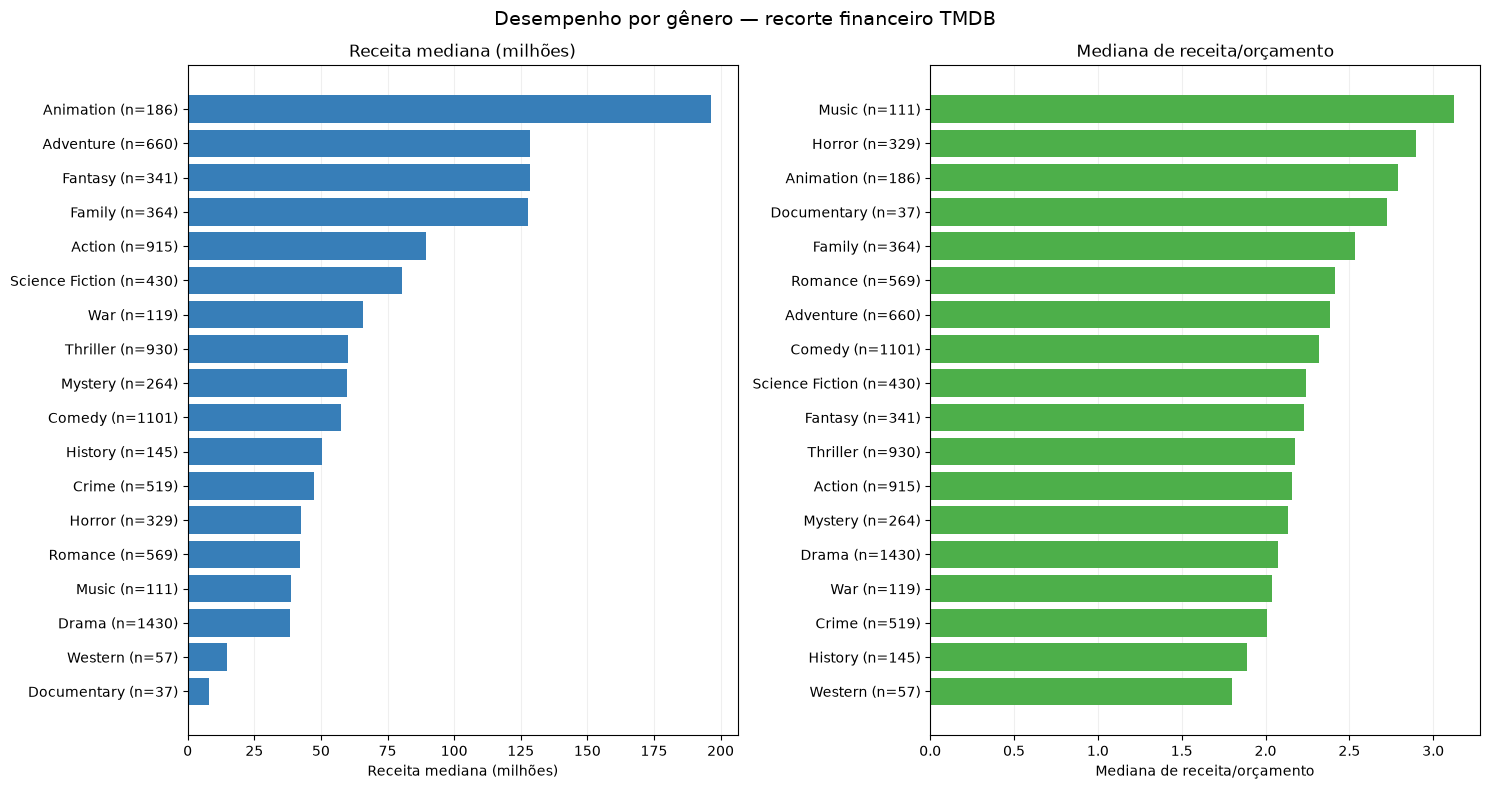

In [16]:
import matplotlib.pyplot as plt

# Regra de apresentação para evitar destacar grupos muito pequenos.
# Não representa garantia de significância estatística.
MIN_FILMES_GENERO = 30

generos_grafico = resumo_generos.loc[
    resumo_generos["filmes"] >= MIN_FILMES_GENERO
].copy()

fig, eixos = plt.subplots(1, 2, figsize=(15, 8))

configuracoes = [
    ("receita_mediana", 1_000_000, "Receita mediana (milhões)", "#377eb8"),
    ("multiplo_mediano", 1, "Mediana de receita/orçamento", "#4daf4a"),
]

for eixo, (coluna, divisor, titulo, cor) in zip(eixos, configuracoes):
    tabela = generos_grafico.sort_values(coluna)

    rotulos = [
        f"{genero} (n={int(quantidade)})"
        for genero, quantidade in tabela["filmes"].items()
    ]

    eixo.barh(rotulos, tabela[coluna] / divisor, color=cor)
    eixo.set_title(titulo)
    eixo.set_xlabel(titulo)
    eixo.grid(axis="x", alpha=0.2)
    eixo.set_axisbelow(True)

fig.suptitle(
    "Desempenho por gênero — recorte financeiro TMDB",
    fontsize=14
)

plt.tight_layout()
plt.show()

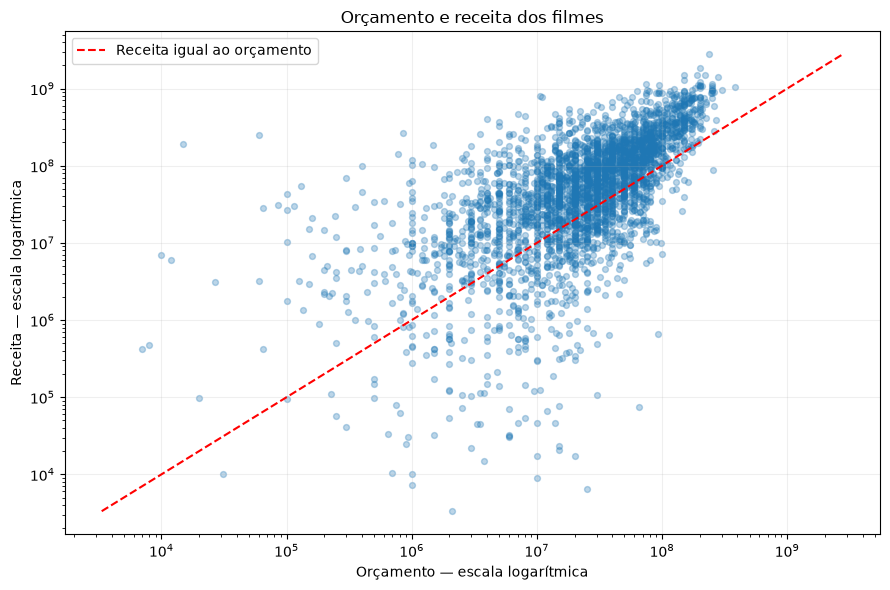

Correlação de Spearman: 0.675


In [17]:
fig, eixo = plt.subplots(figsize=(9, 6))

eixo.scatter(
    cinema_financeiro["budget"],
    cinema_financeiro["revenue"],
    alpha=0.3,
    s=18
)

eixo.set_xscale("log")
eixo.set_yscale("log")

menor = cinema_financeiro[["budget", "revenue"]].min().min()
maior = cinema_financeiro[["budget", "revenue"]].max().max()

eixo.plot(
    [menor, maior],
    [menor, maior],
    linestyle="--",
    color="red",
    label="Receita igual ao orçamento"
)

eixo.set_title("Orçamento e receita dos filmes")
eixo.set_xlabel("Orçamento — escala logarítmica")
eixo.set_ylabel("Receita — escala logarítmica")
eixo.legend()
eixo.grid(alpha=0.2)

plt.tight_layout()
plt.show()

correlacao_spearman = cinema_financeiro["budget"].corr(
    cinema_financeiro["revenue"],
    method="spearman"
)

print(f"Correlação de Spearman: {correlacao_spearman:.3f}")

### Primeiros resultados: orçamento, receita e gêneros

No recorte de 3.211 filmes com orçamento e receita superiores a
1.000, a correlação de Spearman entre essas variáveis foi de 0,675.
Filmes de maior orçamento tendem a apresentar maior receita,
embora exista ampla variação entre filmes de orçamento semelhante.

Animação apresentou a maior receita mediana, de aproximadamente
196,5 milhões. Música e terror apresentaram os maiores múltiplos
medianos de receita/orçamento: 3,12 e 2,90, respectivamente.

Os resultados descrevem o recorte analisado, que representa 66,85%
da base TMDB. Os valores não foram ajustados pela inflação, os
gêneros se sobrepõem e o múltiplo receita/orçamento não representa
lucro. A associação observada não estabelece causalidade.

Filmes com dados financeiros e pelo menos 100 votos: 2708


,relacao,filmes,spearman
0,Orçamento × nota,2708,-0.184
1,Receita × nota,2708,0.080
2,Orçamento × quantidade de votos,2708,0.394


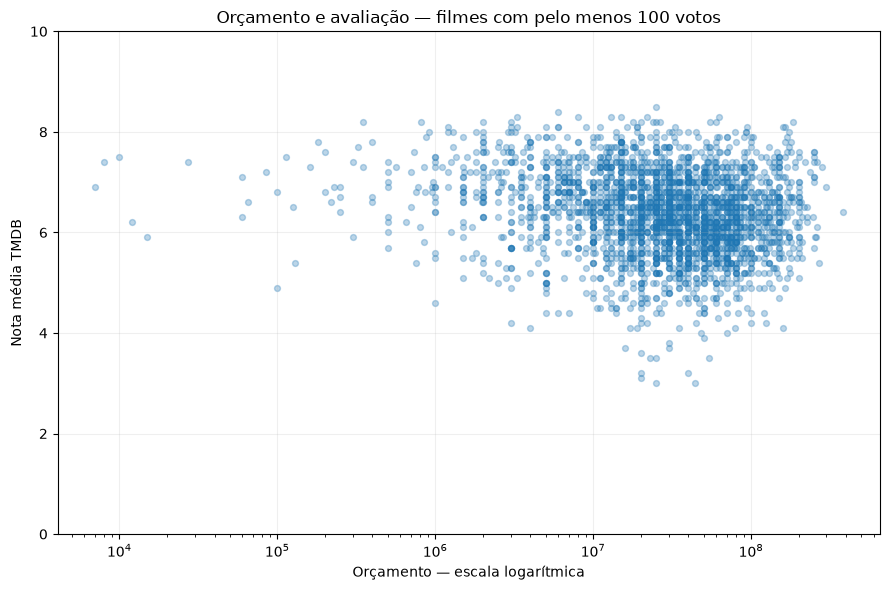

In [18]:
# Exigimos pelo menos 100 votos como critério exploratório.
# Esse limite reduz a influência de notas baseadas em poucos votos,
# mas não garante representatividade.
MIN_VOTOS = 100

cinema_notas = cinema_financeiro.loc[
    cinema_financeiro["vote_count"].ge(MIN_VOTOS)
    & cinema_financeiro["nota_analise"].notna()
].copy()

print("Filmes com dados financeiros e pelo menos 100 votos:", len(cinema_notas))

pares = [
    ("budget", "nota_analise", "Orçamento × nota"),
    ("revenue", "nota_analise", "Receita × nota"),
    ("budget", "vote_count", "Orçamento × quantidade de votos"),
]

resultados = []

for coluna_x, coluna_y, descricao in pares:
    resultados.append({
        "relacao": descricao,
        "filmes": len(cinema_notas),
        "spearman": cinema_notas[coluna_x].corr(
            cinema_notas[coluna_y],
            method="spearman"
        ),
    })

display(pd.DataFrame(resultados).round(3))

fig, eixo = plt.subplots(figsize=(9, 6))

eixo.scatter(
    cinema_notas["budget"],
    cinema_notas["nota_analise"],
    alpha=0.3,
    s=18
)

eixo.set_xscale("log")
eixo.set_ylim(0, 10)
eixo.set_title("Orçamento e avaliação — filmes com pelo menos 100 votos")
eixo.set_xlabel("Orçamento — escala logarítmica")
eixo.set_ylabel("Nota média TMDB")
eixo.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Orçamento, avaliação e participação do público

Entre os 2.708 filmes do recorte financeiro com pelo menos
100 votos, o orçamento apresentou associação negativa fraca
com a nota média TMDB (Spearman = −0,184).

A relação entre receita e nota foi muito fraca (0,080).
Já orçamento e quantidade de votos apresentaram associação
positiva (0,394).

Nesse recorte, maior orçamento não esteve associado a melhores
avaliações, embora tenha acompanhado maior volume de votos.
Quantidade de votos não equivale ao total de espectadores.

Os resultados são descritivos e não estabelecem causalidade.

In [19]:
sensibilidade_votos = []

for minimo in [1, 50, 100, 500]:
    recorte = cinema_financeiro.loc[
        cinema_financeiro["vote_count"].ge(minimo)
        & cinema_financeiro["nota_analise"].notna()
    ]

    sensibilidade_votos.append({
        "minimo_votos": minimo,
        "filmes": len(recorte),
        "orcamento_x_nota": recorte["budget"].corr(
            recorte["nota_analise"], method="spearman"
        ),
        "receita_x_nota": recorte["revenue"].corr(
            recorte["nota_analise"], method="spearman"
        ),
        "orcamento_x_votos": recorte["budget"].corr(
            recorte["vote_count"], method="spearman"
        ),
    })

display(pd.DataFrame(sensibilidade_votos).round(3))

,minimo_votos,filmes,orcamento_x_nota,receita_x_nota,orcamento_x_votos
0,1,3209,-0.139,0.126,0.478
1,50,2951,-0.177,0.091,0.425
2,100,2708,-0.184,0.080,0.394
3,500,1561,-0.251,-0.044,0.360


A análise de sensibilidade com mínimos de 1, 50, 100 e 500 votos
manteve a associação negativa fraca entre orçamento e nota.
A relação entre receita e nota permaneceu próxima de zero,
com mudança de sinal no recorte de 500 votos.

Orçamento e quantidade de votos apresentaram associação positiva
em todos os cenários. As diferenças entre os coeficientes refletem
também mudanças na composição dos filmes analisados.

In [20]:
resumo_avaliacoes = (
    avaliacoes_tratadas
    .groupby("movieId", as_index=False)
    .agg(
        quantidade_avaliacoes=("rating", "size"),
        nota_media=("rating", "mean"),
        nota_mediana=("rating", "median"),
    )
)

filmes_avaliados = filmes_tratados.merge(
    resumo_avaliacoes,
    on="movieId",
    how="left",
    validate="one_to_one"
)

# Sem avaliação significa quantidade zero, mas a nota fica ausente.
filmes_avaliados["quantidade_avaliacoes"] = (
    filmes_avaliados["quantidade_avaliacoes"]
    .fillna(0)
    .astype(int)
)

assert len(filmes_avaliados) == len(filmes_tratados)
assert (
    filmes_avaliados["quantidade_avaliacoes"].sum()
    == len(avaliacoes_tratadas)
)

print("Filmes no cadastro:", len(filmes_avaliados))
print(
    "Filmes sem avaliações:",
    filmes_avaliados["quantidade_avaliacoes"].eq(0).sum()
)
print(
    "Nota média de todas as avaliações:",
    round(avaliacoes_tratadas["rating"].mean(), 3)
)

Filmes no cadastro: 9742
Filmes sem avaliações: 18
Nota média de todas as avaliações: 3.502


In [21]:
colunas_ranking = [
    "title", "quantidade_avaliacoes", "nota_media"
]

print("10 filmes com mais avaliações:")

display(
    filmes_avaliados
    .sort_values(
        ["quantidade_avaliacoes", "nota_media", "movieId"],
        ascending=[False, False, True]
    )
    [colunas_ranking]
    .head(10)
    .round(2)
)

MIN_AVALIACOES = 50  # Critério exploratório para este ranking.

print(f"\n10 maiores notas entre filmes com pelo menos {MIN_AVALIACOES} avaliações:")

display(
    filmes_avaliados.loc[
        filmes_avaliados["quantidade_avaliacoes"] >= MIN_AVALIACOES
    ]
    .sort_values(
        ["nota_media", "quantidade_avaliacoes", "movieId"],
        ascending=[False, False, True]
    )
    [colunas_ranking]
    .head(10)
    .round(2)
)

print(
    "\nFilmes elegíveis ao ranking de notas:",
    filmes_avaliados["quantidade_avaliacoes"].ge(MIN_AVALIACOES).sum()
)

10 filmes com mais avaliações:


,title,quantidade_avaliacoes,nota_media
314,Forrest Gump (1994),329,4.16
277,"Shawshank Redemption, The (1994)",317,4.43
257,Pulp Fiction (1994),307,4.20
510,"Silence of the Lambs, The (1991)",279,4.16
1939,"Matrix, The (1999)",278,4.19
224,Star Wars: Episode IV - A New Hope (1977),251,4.23
418,Jurassic Park (1993),238,3.75
97,Braveheart (1995),237,4.03
507,Terminator 2: Judgment Day (1991),224,3.97
461,Schindler's List (1993),220,4.22



10 maiores notas entre filmes com pelo menos 50 avaliações:


,title,quantidade_avaliacoes,nota_media
277,"Shawshank Redemption, The (1994)",317,4.43
659,"Godfather, The (1972)",192,4.29
2226,Fight Club (1999),218,4.27
975,Cool Hand Luke (1967),57,4.27
602,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.27
686,Rear Window (1954),84,4.26
922,"Godfather: Part II, The (1974)",129,4.26
6315,"Departed, The (2006)",107,4.25
914,Goodfellas (1990),126,4.25
694,Casablanca (1942),100,4.24



Filmes elegíveis ao ranking de notas: 450


### Filmes mais avaliados e maiores notas

Forrest Gump apresentou o maior volume de avaliações: 329,
com nota média de 4,16. The Shawshank Redemption apresentou
a maior nota média entre os filmes com pelo menos 50 avaliações:
4,43, com 317 avaliações.

O critério mínimo selecionou 450 filmes, aproximadamente 4,63%
dos 9.724 títulos avaliados. Os resultados descrevem as avaliações
dos usuários presentes na amostra e não representam necessariamente
as preferências de todo o público.

In [22]:
filmes_generos = (
    filmes_avaliados[
        ["movieId", "generos_lista", "quantidade_avaliacoes", "nota_media"]
    ]
    .explode("generos_lista")
    .rename(columns={"generos_lista": "genero"})
    .dropna(subset=["genero"])
    .drop_duplicates(subset=["movieId", "genero"])
)

# Recupera a soma das notas de cada filme.
filmes_generos["soma_notas"] = (
    filmes_generos["nota_media"]
    * filmes_generos["quantidade_avaliacoes"]
)

resumo_generos_publico = (
    filmes_generos
    .groupby("genero")
    .agg(
        filmes_cadastrados=("movieId", "nunique"),
        filmes_avaliados=(
            "quantidade_avaliacoes",
            lambda coluna: coluna.gt(0).sum()
        ),
        quantidade_avaliacoes=("quantidade_avaliacoes", "sum"),
        soma_notas=("soma_notas", "sum"),
        media_por_filme=("nota_media", "mean"),
    )
)

resumo_generos_publico["media_por_avaliacao"] = (
    resumo_generos_publico["soma_notas"]
    / resumo_generos_publico["quantidade_avaliacoes"].replace(0, float("nan"))
)

display(
    resumo_generos_publico
    .drop(columns="soma_notas")
    .sort_values("quantidade_avaliacoes", ascending=False)
    .round(3)
)

,filmes_cadastrados,filmes_avaliados,quantidade_avaliacoes,media_por_filme,media_por_avaliacao
genero,,,,,
Drama,4361,4349,41928,3.421,3.656
Comedy,3756,3753,39053,3.182,3.385
Action,1828,1828,30635,3.094,3.448
Thriller,1894,1889,26452,3.156,3.494
Adventure,1263,1262,24161,3.215,3.509
Romance,1596,1591,18124,3.365,3.507
Sci-Fi,980,980,17243,3.103,3.456
Crime,1199,1196,16681,3.302,3.658
Fantasy,779,778,11834,3.219,3.491


### Avaliações por gênero

Drama concentrou o maior volume de avaliações (41.928).
Film-Noir apresentou a maior média por avaliação (3,920),
enquanto Documentary liderou na média das notas por filme (3,782).

Em todos os gêneros, a média por avaliação superou a média por
filme. Assim, os filmes mais avaliados elevaram a média quando
receberam peso proporcional à quantidade de avaliações.

Os gêneros se sobrepõem e apresentam tamanhos diferentes.
As notas refletem os usuários e filmes desta amostra; as
diferenças observadas não demonstram preferência universal
nem efeito causal do gênero sobre a avaliação.

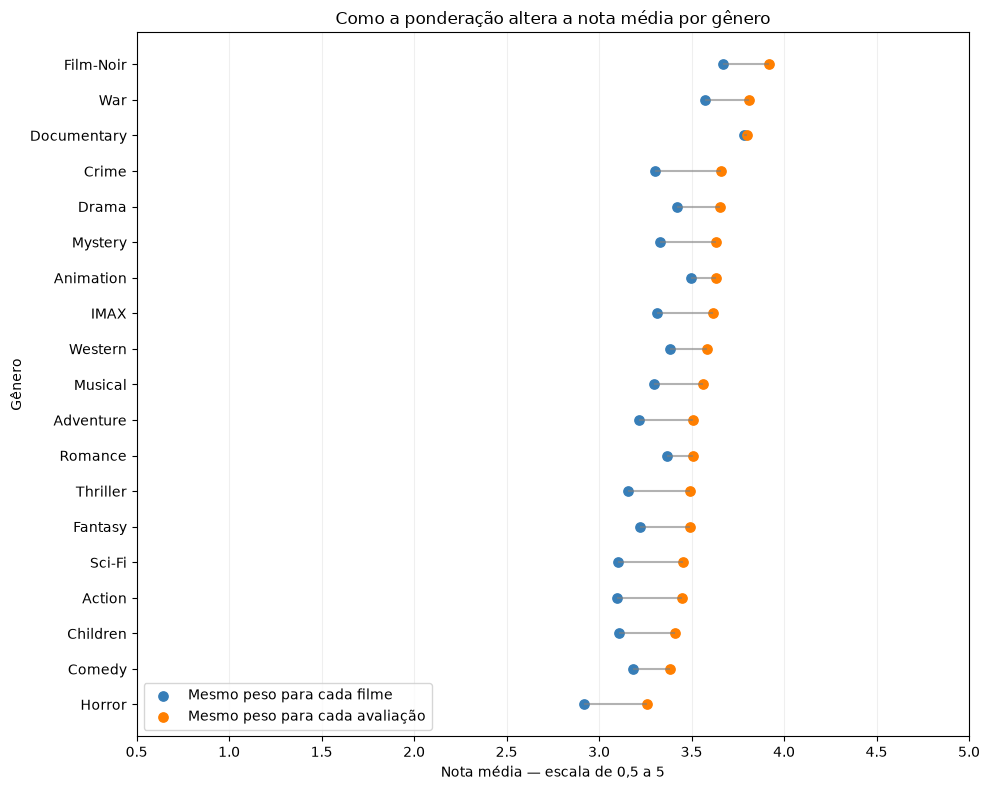

In [23]:
tabela = resumo_generos_publico.sort_values("media_por_avaliacao")

fig, eixo = plt.subplots(figsize=(10, 8))

eixo.hlines(
    y=tabela.index,
    xmin=tabela["media_por_filme"],
    xmax=tabela["media_por_avaliacao"],
    color="gray",
    alpha=0.6
)

eixo.scatter(
    tabela["media_por_filme"],
    tabela.index,
    label="Mesmo peso para cada filme",
    color="#377eb8",
    s=45
)

eixo.scatter(
    tabela["media_por_avaliacao"],
    tabela.index,
    label="Mesmo peso para cada avaliação",
    color="#ff7f00",
    s=45
)

eixo.set_xlim(0.5, 5)
eixo.set_xlabel("Nota média — escala de 0,5 a 5")
eixo.set_ylabel("Gênero")
eixo.set_title("Como a ponderação altera a nota média por gênero")
eixo.legend(loc="lower left")
eixo.grid(axis="x", alpha=0.2)
eixo.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [24]:
pasta_original = Path.home() / "Downloads" / "ml-latest-small"

filmes_oficiais = pd.read_csv(pasta_original / "movies.csv")
avaliacoes_oficiais = pd.read_csv(pasta_original / "ratings.csv")

def comparar_bases(base_atual, base_oficial, chaves):
    atual = base_atual.sort_values(chaves).reset_index(drop=True)
    oficial = base_oficial.sort_values(chaves).reset_index(drop=True)

    pd.testing.assert_frame_equal(
        atual,
        oficial,
        check_dtype=False
    )

comparar_bases(filmes, filmes_oficiais, ["movieId"])
comparar_bases(
    avaliacoes,
    avaliacoes_oficiais,
    ["userId", "movieId"]
)

print("Confirmado: filmes e avaliações coincidem com a distribuição oficial.")

Confirmado: filmes e avaliações coincidem com a distribuição oficial.


In [25]:
links = pd.read_csv(
    pasta_dados / "links.csv",
    dtype={
        "movieId": "Int64",
        "imdbId": "string",
        "tmdbId": "Int64",
    }
)

display(links.head())

print("Linhas:", len(links))
print("movieId ausentes:", links["movieId"].isna().sum())
print("movieId repetidos:", links["movieId"].duplicated().sum())
print("tmdbId ausentes:", links["tmdbId"].isna().sum())

print(
    "Filmes do nosso cadastro sem correspondência em links:",
    (~filmes_tratados["movieId"].isin(links["movieId"])).sum()
)

print(
    "tmdbId distintos presentes na nossa TMDB:",
    links.loc[
        links["tmdbId"].isin(tmdb_tratado["id"]),
        "tmdbId"
    ].nunique()
)

,movieId,imdbId,tmdbId
0,1,0114709,862
1,2,0113497,8844
2,3,0113228,15602
3,4,0114885,31357
4,5,0113041,11862


Linhas: 9742
movieId ausentes: 0
movieId repetidos: 0
tmdbId ausentes: 8
Filmes do nosso cadastro sem correspondência em links: 0
tmdbId distintos presentes na nossa TMDB: 3536


In [26]:
links_validos = links.dropna(subset=["tmdbId"]).copy()

tmdb_ids_repetidos = links_validos.loc[
    links_validos["tmdbId"].duplicated(keep=False)
].sort_values(["tmdbId", "movieId"])

print(
    "IDs TMDB associados a mais de um movieId:",
    tmdb_ids_repetidos["tmdbId"].nunique()
)

display(tmdb_ids_repetidos)

IDs TMDB associados a mais de um movieId: 1


,movieId,imdbId,tmdbId
4169,6003,0290538,4912
9106,144606,0270288,4912


In [27]:
filmes_com_links = filmes_avaliados.merge(
    links[["movieId", "imdbId", "tmdbId"]],
    on="movieId",
    how="left",
    validate="one_to_one"
)

base_integrada = filmes_com_links.merge(
    tmdb_tratado,
    left_on="tmdbId",
    right_on="id",
    how="left",
    suffixes=("_movielens", "_tmdb"),
    validate="many_to_one",
    indicator="correspondencia_tmdb"
)

assert len(base_integrada) == len(filmes_avaliados)

assert (
    base_integrada["quantidade_avaliacoes"].sum()
    == len(avaliacoes_tratadas)
)

print("Filmes preservados:", len(base_integrada))

print(
    "Filmes MovieLens com correspondência na TMDB:",
    base_integrada["correspondencia_tmdb"].eq("both").sum()
)

print(
    "Filmes TMDB distintos encontrados:",
    base_integrada["id"].nunique()
)

display(
    base_integrada.loc[
        base_integrada["correspondencia_tmdb"].eq("both"),
        [
            "movieId", "tmdbId",
            "title_movielens", "title_tmdb",
            "quantidade_avaliacoes", "nota_media", "nota_analise"
        ]
    ].head(15)
)

Filmes preservados: 9742
Filmes MovieLens com correspondência na TMDB: 3537
Filmes TMDB distintos encontrados: 3536


,movieId,tmdbId,title_movielens,title_tmdb,quantidade_avaliacoes,nota_media,nota_analise
0,1,862,Toy Story (1995),Toy Story,215,3.920930,7.7
9,10,710,GoldenEye (1995),GoldenEye,132,3.496212,6.6
10,11,9087,"American President, The (1995)",The American President,70,3.671429,6.5
13,14,10858,Nixon (1995),Nixon,18,3.833333,7.1
14,15,1408,Cutthroat Island (1995),Cutthroat Island,13,3.000000,5.7
15,16,524,Casino (1995),Casino,82,3.926829,7.8
16,17,4584,Sense and Sensibility (1995),Sense and Sensibility,67,3.776119,7.2
17,18,5,Four Rooms (1995),Four Rooms,20,3.700000,6.5
18,19,9273,Ace Ventura: When Nature Calls (1995),Ace Ventura: When Nature Calls,88,2.727273,6.1
19,20,11517,Money Train (1995),Money Train,15,2.500000,5.4


In [28]:
display(
    base_integrada.loc[
        base_integrada["tmdbId"].eq(4912),
        [
            "movieId", "imdbId", "tmdbId",
            "title_movielens", "title_tmdb",
            "original_title", "ano_lancamento",
            "quantidade_avaliacoes", "nota_media"
        ]
    ]
)

,movieId,imdbId,tmdbId,title_movielens,title_tmdb,original_title,ano_lancamento,quantidade_avaliacoes,nota_media
4169,6003,0290538,4912,Confessions of a Dangerous Mind (2002),Confessions of a Dangerous Mind,Confessions of a Dangerous Mind,2002,15,3.6
9106,144606,0270288,4912,Confessions of a Dangerous Mind (2002),Confessions of a Dangerous Mind,Confessions of a Dangerous Mind,2002,1,4.0


In [29]:
ids_tmdb_ambiguos = tmdb_ids_repetidos["tmdbId"].unique()

integracao_unica = base_integrada.loc[
    base_integrada["correspondencia_tmdb"].eq("both")
    & ~base_integrada["tmdbId"].isin(ids_tmdb_ambiguos)
].copy()

assert integracao_unica["movieId"].is_unique
assert integracao_unica["tmdbId"].is_unique

print("Correspondências sem ambiguidade de ID:", len(integracao_unica))

Correspondências sem ambiguidade de ID: 3535


In [30]:
integracao_unica["ano_movielens"] = (
    integracao_unica["title_movielens"]
    .str.extract(r"\((\d{4})\)\s*$", expand=False)
    .astype("Int64")
)

anos_comparaveis = (
    integracao_unica["ano_movielens"].notna()
    & integracao_unica["ano_lancamento"].notna()
)

divergencias_ano = integracao_unica.loc[
    anos_comparaveis
    & integracao_unica["ano_movielens"].ne(
        integracao_unica["ano_lancamento"]
    )
].copy()

print("Filmes com anos comparáveis:", anos_comparaveis.sum())
print("Filmes com anos diferentes:", len(divergencias_ano))

display(
    divergencias_ano[
        [
            "movieId", "tmdbId",
            "title_movielens", "title_tmdb",
            "ano_movielens", "ano_lancamento"
        ]
    ].head(20)
)

Filmes com anos comparáveis: 3535
Filmes com anos diferentes: 66


,movieId,tmdbId,title_movielens,title_tmdb,ano_movielens,ano_lancamento
191,224,1909,Don Juan DeMarco (1995),Don Juan DeMarco,1995,1994
420,482,507,Killing Zoe (1994),Killing Zoe,1994,1993
859,1130,11298,"Howling, The (1980)",The Howling,1980,1981
916,1215,766,Army of Darkness (1993),Army of Darkness,1993,1992
994,1296,11257,"Room with a View, A (1986)",A Room with a View,1986,1985
1629,2175,161795,Déjà Vu (1997),Déjà Vu,1997,1998
2403,3189,17908,My Dog Skip (1999),My Dog Skip,1999,2000
2462,3275,8374,"Boondock Saints, The (2000)",The Boondock Saints,2000,1999
2750,3688,10246,Porky's (1982),Porky's,1982,1981
2755,3693,15239,"Toxic Avenger, The (1985)",The Toxic Avenger,1985,1984


In [31]:
divergencias_ano["diferenca_ano"] = (
    divergencias_ano["ano_movielens"]
    - divergencias_ano["ano_lancamento"]
)

print("Distribuição das diferenças de ano:")

display(
    divergencias_ano["diferenca_ano"]
    .value_counts()
    .sort_index()
    .rename_axis("diferenca_ano")
    .to_frame("filmes")
)

print("Casos com diferença superior a um ano:")

display(
    divergencias_ano.loc[
        divergencias_ano["diferenca_ano"].abs() > 1,
        [
            "movieId", "tmdbId",
            "title_movielens", "title_tmdb",
            "ano_movielens", "ano_lancamento"
        ]
    ]
)

Distribuição das diferenças de ano:


,filmes
diferenca_ano,
-2,1
-1,31
1,33
2,1


Casos com diferença superior a um ano:


,movieId,tmdbId,title_movielens,title_tmdb,ano_movielens,ano_lancamento
6759,59738,9022,All the Boys Love Mandy Lane (2006),All the Boys Love Mandy Lane,2006,2008
7140,71379,23827,Paranormal Activity (2009),Paranormal Activity,2009,2007


Filmes na comparação: 383
Spearman entre as notas: 0.882


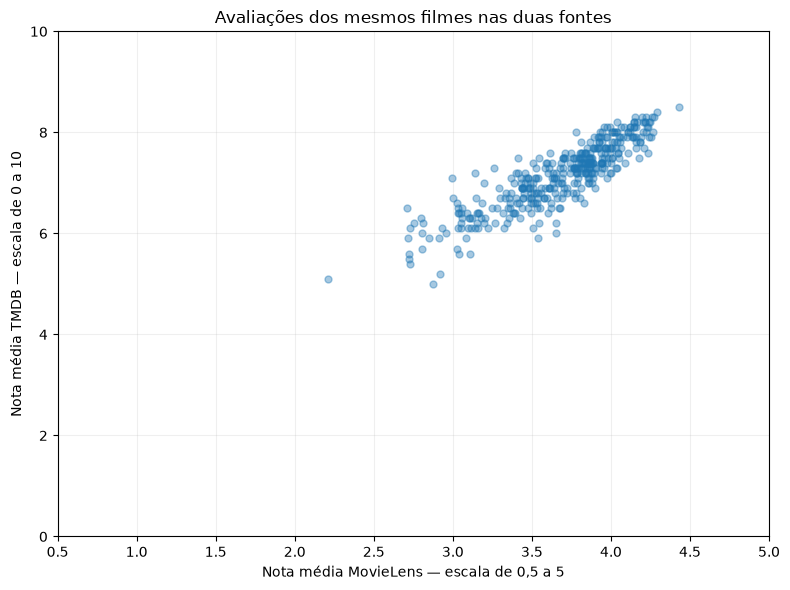

In [32]:
comparacao_notas = integracao_unica.loc[
    integracao_unica["quantidade_avaliacoes"].ge(50)
    & integracao_unica["vote_count"].ge(100)
    & integracao_unica["nota_media"].notna()
    & integracao_unica["nota_analise"].notna()
].copy()

correlacao_fontes = comparacao_notas["nota_media"].corr(
    comparacao_notas["nota_analise"],
    method="spearman"
)

print("Filmes na comparação:", len(comparacao_notas))
print(f"Spearman entre as notas: {correlacao_fontes:.3f}")

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.scatter(
    comparacao_notas["nota_media"],
    comparacao_notas["nota_analise"],
    alpha=0.4,
    s=25
)

eixo.set_xlim(0.5, 5)
eixo.set_ylim(0, 10)
eixo.set_xlabel("Nota média MovieLens — escala de 0,5 a 5")
eixo.set_ylabel("Nota média TMDB — escala de 0 a 10")
eixo.set_title("Avaliações dos mesmos filmes nas duas fontes")
eixo.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparação das avaliações entre MovieLens e TMDB

Entre os 383 filmes com pelo menos 50 avaliações no MovieLens
e 100 votos na TMDB, a correlação de Spearman entre as notas
foi de 0,882. O resultado indica forte associação positiva na
ordenação das avaliações dos filmes entre as fontes.

Essa associação não significa igualdade das notas nem
equivalência entre os públicos. As fontes possuem escalas,
participantes e períodos de coleta diferentes.

Na integração sem IDs ambíguos, 66 filmes apresentaram anos
de lançamento divergentes: 64 com diferença de um ano e dois
com diferença de dois anos. As datas originais foram preservadas.
Dois registros MovieLens ligados ao mesmo ID TMDB permaneceram
fora da comparação por ambiguidade de correspondência.

In [33]:
cenarios_fontes = []

for minimo_ml in [10, 25, 50, 100]:
    recorte = integracao_unica.loc[
        integracao_unica["quantidade_avaliacoes"].ge(minimo_ml)
        & integracao_unica["vote_count"].ge(100)
        & integracao_unica["nota_media"].notna()
        & integracao_unica["nota_analise"].notna()
    ]

    cenarios_fontes.append({
        "minimo_avaliacoes_movielens": minimo_ml,
        "minimo_votos_tmdb": 100,
        "filmes": len(recorte),
        "spearman": recorte["nota_media"].corr(
            recorte["nota_analise"],
            method="spearman"
        ),
    })

display(pd.DataFrame(cenarios_fontes).round(3))

,minimo_avaliacoes_movielens,minimo_votos_tmdb,filmes,spearman
0,10,100,1495,0.853
1,25,100,812,0.860
2,50,100,383,0.882
3,100,100,125,0.913


A associação positiva entre as notas se manteve nos quatro
cenários de participação analisados, com Spearman entre
0,853 e 0,913, mantendo o mínimo de 100 votos na TMDB.

Limites maiores no MovieLens produziram correlações mais altas,
mas também reduziram e alteraram o conjunto de filmes.

In [34]:
import sqlite3

# Filmes TMDB: uma linha por filme.
sql_tmdb = tmdb_tratado[
    [
        "id", "title", "ano_lancamento",
        "orcamento_analise", "receita_analise",
        "duracao_analise", "nota_analise", "vote_count",
        "incluido_recorte_financeiro"
    ]
].rename(columns={
    "id": "tmdb_id",
    "title": "titulo",
    "nota_analise": "nota_tmdb",
    "vote_count": "quantidade_votos_tmdb",
})

# Filmes MovieLens: uma linha por filme.
sql_movielens = filmes_avaliados[
    ["movieId", "title", "quantidade_avaliacoes", "nota_media"]
].rename(columns={
    "movieId": "movie_id",
    "title": "titulo",
    "nota_media": "nota_movielens",
})

# Avaliações individuais.
sql_avaliacoes = avaliacoes_tratadas[
    ["userId", "movieId", "rating", "timestamp"]
].rename(columns={
    "userId": "usuario_id",
    "movieId": "movie_id",
    "rating": "nota",
    "timestamp": "timestamp_unix",
})

sql_tmdb_generos = tmdb_generos.rename(
    columns={"id": "tmdb_id"}
)

sql_movielens_generos = filmes_generos[
    ["movieId", "genero"]
].rename(columns={"movieId": "movie_id"})

# Apenas correspondências sem ambiguidade de ID.
sql_correspondencias = integracao_unica[
    ["movieId", "tmdbId"]
].rename(columns={
    "movieId": "movie_id",
    "tmdbId": "tmdb_id",
})

In [35]:
conexao = sqlite3.connect(":memory:")

tabelas_sql = {
    "filmes_tmdb": sql_tmdb,
    "filmes_movielens": sql_movielens,
    "avaliacoes": sql_avaliacoes,
    "generos_tmdb": sql_tmdb_generos,
    "generos_movielens": sql_movielens_generos,
    "correspondencias": sql_correspondencias,
}

for nome, tabela in tabelas_sql.items():
    tabela.to_sql(
        nome,
        conexao,
        index=False,
        if_exists="replace"
    )

    quantidade = conexao.execute(
        f'SELECT COUNT(*) FROM "{nome}"'
    ).fetchone()[0]

    assert quantidade == len(tabela)

    print(f"{nome}: {quantidade:,} linhas")

filmes_tmdb: 4,803 linhas
filmes_movielens: 9,742 linhas
avaliacoes: 100,836 linhas
generos_tmdb: 12,160 linhas
generos_movielens: 22,050 linhas
correspondencias: 3,535 linhas


In [36]:
consulta = """
SELECT
    f.movie_id,
    f.titulo,
    COUNT(*) AS quantidade_avaliacoes,
    AVG(a.nota) AS nota_media
FROM filmes_movielens AS f
INNER JOIN avaliacoes AS a
    ON f.movie_id = a.movie_id
GROUP BY
    f.movie_id,
    f.titulo
HAVING COUNT(*) >= 50
ORDER BY
    nota_media DESC,
    quantidade_avaliacoes DESC,
    f.movie_id ASC
LIMIT 10;
"""

ranking_sql = pd.read_sql_query(consulta, conexao)

display(ranking_sql.round(2))

,movie_id,titulo,quantidade_avaliacoes,nota_media
0,318,"Shawshank Redemption, The (1994)",317,4.43
1,858,"Godfather, The (1972)",192,4.29
2,2959,Fight Club (1999),218,4.27
3,1276,Cool Hand Luke (1967),57,4.27
4,750,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.27
5,904,Rear Window (1954),84,4.26
6,1221,"Godfather: Part II, The (1974)",129,4.26
7,48516,"Departed, The (2006)",107,4.25
8,1213,Goodfellas (1990),126,4.25
9,912,Casablanca (1942),100,4.24


In [37]:
ranking_pandas = (
    filmes_avaliados.loc[
        filmes_avaliados["quantidade_avaliacoes"].ge(50)
    ]
    .sort_values(
        ["nota_media", "quantidade_avaliacoes", "movieId"],
        ascending=[False, False, True]
    )
    .head(10)
    [["movieId", "title", "quantidade_avaliacoes", "nota_media"]]
    .rename(columns={
        "movieId": "movie_id",
        "title": "titulo",
    })
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    ranking_sql.reset_index(drop=True),
    ranking_pandas,
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)

print("Validado: SQL e Pandas produziram o mesmo ranking.")

Validado: SQL e Pandas produziram o mesmo ranking.


In [38]:
consulta_comparacao = """
SELECT
    ml.movie_id,
    t.tmdb_id,
    ml.titulo AS titulo_movielens,
    t.titulo AS titulo_tmdb,
    ml.quantidade_avaliacoes,
    ml.nota_movielens,
    t.quantidade_votos_tmdb,
    t.nota_tmdb
FROM correspondencias AS c
INNER JOIN filmes_movielens AS ml
    ON c.movie_id = ml.movie_id
INNER JOIN filmes_tmdb AS t
    ON c.tmdb_id = t.tmdb_id
WHERE ml.quantidade_avaliacoes >= 50
  AND t.quantidade_votos_tmdb >= 100
  AND ml.nota_movielens IS NOT NULL
  AND t.nota_tmdb IS NOT NULL
ORDER BY ml.movie_id;
"""

comparacao_sql = pd.read_sql_query(
    consulta_comparacao,
    conexao
)

assert len(comparacao_sql) == len(comparacao_notas)

print("Filmes na comparação SQL:", len(comparacao_sql))
display(comparacao_sql.head(10).round(3))

Filmes na comparação SQL: 383


,movie_id,tmdb_id,titulo_movielens,titulo_tmdb,quantidade_avaliacoes,nota_movielens,quantidade_votos_tmdb,nota_tmdb
0,1,862,Toy Story (1995),Toy Story,215,3.921,5269,7.7
1,10,710,GoldenEye (1995),GoldenEye,132,3.496,1174,6.6
2,11,9087,"American President, The (1995)",The American President,70,3.671,195,6.5
3,16,524,Casino (1995),Casino,82,3.927,1307,7.8
4,17,4584,Sense and Sensibility (1995),Sense and Sensibility,67,3.776,352,7.2
5,19,9273,Ace Ventura: When Nature Calls (1995),Ace Ventura: When Nature Calls,88,2.727,1099,6.1
6,21,8012,Get Shorty (1995),Get Shorty,89,3.494,302,6.4
7,25,451,Leaving Las Vegas (1995),Leaving Las Vegas,76,3.625,360,7.1
8,34,9598,Babe (1995),Babe,128,3.652,733,6.0
9,36,687,Dead Man Walking (1995),Dead Man Walking,67,3.836,337,7.3


In [39]:
consulta_generos = """
SELECT
    g.genero,
    COUNT(*) AS filmes_cadastrados,
    SUM(
        CASE WHEN f.quantidade_avaliacoes > 0 THEN 1 ELSE 0 END
    ) AS filmes_avaliados,
    SUM(f.quantidade_avaliacoes) AS quantidade_avaliacoes,
    AVG(f.nota_movielens) AS media_por_filme,
    SUM(f.nota_movielens * f.quantidade_avaliacoes)
        / NULLIF(SUM(f.quantidade_avaliacoes), 0)
        AS media_por_avaliacao
FROM generos_movielens AS g
INNER JOIN filmes_movielens AS f
    ON g.movie_id = f.movie_id
GROUP BY g.genero
ORDER BY quantidade_avaliacoes DESC;
"""

generos_sql = pd.read_sql_query(consulta_generos, conexao)

display(generos_sql.round(3))

,genero,filmes_cadastrados,filmes_avaliados,quantidade_avaliacoes,media_por_filme,media_por_avaliacao
0,Drama,4361,4349,41928,3.421,3.656
1,Comedy,3756,3753,39053,3.182,3.385
2,Action,1828,1828,30635,3.094,3.448
3,Thriller,1894,1889,26452,3.156,3.494
4,Adventure,1263,1262,24161,3.215,3.509
5,Romance,1596,1591,18124,3.365,3.507
6,Sci-Fi,980,980,17243,3.103,3.456
7,Crime,1199,1196,16681,3.302,3.658
8,Fantasy,779,778,11834,3.219,3.491
9,Children,664,664,9208,3.108,3.413


In [40]:
# As pastas serão criadas dentro de Projeto_C_Analise_Cinema.
pasta_projeto = pasta_dados.parent
pasta_processados = pasta_dados / "processados"
pasta_sql = pasta_projeto / "sql"

pasta_processados.mkdir(parents=True, exist_ok=True)
pasta_sql.mkdir(parents=True, exist_ok=True)

# Salvar o banco que está em memória.
caminho_banco = pasta_processados / "cinema.sqlite"

conexao.commit()

with sqlite3.connect(caminho_banco) as banco_destino:
    conexao.backup(banco_destino)

# Exportar as mesmas tabelas para uso no Power BI.
for nome, tabela in tabelas_sql.items():
    tabela.to_csv(
        pasta_processados / f"{nome}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# Salvar as consultas.
consultas = {
    "01_ranking_filmes.sql": consulta,
    "02_comparacao_fontes.sql": consulta_comparacao,
    "03_avaliacoes_por_genero.sql": consulta_generos,
}

for nome, texto in consultas.items():
    (pasta_sql / nome).write_text(
        texto.strip() + "\n",
        encoding="utf-8"
    )

# Preservar os casos separados para revisão.
base_integrada.loc[
    base_integrada["tmdbId"].isin(ids_tmdb_ambiguos),
    [
        "movieId", "imdbId", "tmdbId",
        "title_movielens", "title_tmdb",
        "quantidade_avaliacoes", "nota_media"
    ]
].to_csv(
    pasta_processados / "auditoria_correspondencias_ambiguas.csv",
    index=False,
    encoding="utf-8-sig"
)

divergencias_ano.to_csv(
    pasta_processados / "auditoria_divergencias_ano.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Banco salvo em:", caminho_banco)
print("CSVs salvos em:", pasta_processados)
print("Consultas salvas em:", pasta_sql)

Banco salvo em: c:\Users\milan\Projeto_C_Analise_Cinema\dados\processados\cinema.sqlite
CSVs salvos em: c:\Users\milan\Projeto_C_Analise_Cinema\dados\processados
Consultas salvas em: c:\Users\milan\Projeto_C_Analise_Cinema\sql


In [41]:
with sqlite3.connect(caminho_banco) as banco_salvo:
    for nome, tabela in tabelas_sql.items():
        quantidade = banco_salvo.execute(
            f'SELECT COUNT(*) FROM "{nome}"'
        ).fetchone()[0]

        assert quantidade == len(tabela), f"Contagem divergente: {nome}"

    comparacao_salva = pd.read_sql_query(
        consulta_comparacao,
        banco_salvo
    )

pd.testing.assert_frame_equal(
    comparacao_salva,
    comparacao_sql,
    check_dtype=False
)

print("Validado: banco reaberto, contagens e consulta preservadas.")

Validado: banco reaberto, contagens e consulta preservadas.
